<a href="https://colab.research.google.com/github/BhuvanHande/ML-Lab/blob/main/ALM_Midsem.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [24]:
import pandas as pd
import numpy as np

url = "https://archive.ics.uci.edu/ml/machine-learning-databases/adult/adult.data"

columns = [
    "age", "workclass", "fnlwgt", "education",
    "education_num", "marital_status", "occupation",
    "relationship", "race", "sex", "capital_gain",
    "capital_loss", "hours_per_week", "native_country",
    "income"
]

df = pd.read_csv(
    url,
    names=columns,
    skipinitialspace=True,
    na_values="?"
)

print(df.head())
print("Dataset shape:", df.shape)

   age         workclass  fnlwgt  education  education_num  \
0   39         State-gov   77516  Bachelors             13   
1   50  Self-emp-not-inc   83311  Bachelors             13   
2   38           Private  215646    HS-grad              9   
3   53           Private  234721       11th              7   
4   28           Private  338409  Bachelors             13   

       marital_status         occupation   relationship   race     sex  \
0       Never-married       Adm-clerical  Not-in-family  White    Male   
1  Married-civ-spouse    Exec-managerial        Husband  White    Male   
2            Divorced  Handlers-cleaners  Not-in-family  White    Male   
3  Married-civ-spouse  Handlers-cleaners        Husband  Black    Male   
4  Married-civ-spouse     Prof-specialty           Wife  Black  Female   

   capital_gain  capital_loss  hours_per_week native_country income  
0          2174             0              40  United-States  <=50K  
1             0             0             

In [3]:
numerical_features = df.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = df.select_dtypes(
    include=["object", "category"]
).columns.tolist()

print("Numerical features:", numerical_features)
print("Categorical features:", categorical_features)

Numerical features: ['age', 'fnlwgt', 'education_num', 'capital_gain', 'capital_loss', 'hours_per_week']
Categorical features: ['workclass', 'education', 'marital_status', 'occupation', 'relationship', 'race', 'sex', 'native_country', 'income']


In [4]:
print("Missing values per column:")
print(df.isnull().sum())

print("\nTotal missing values:", df.isnull().sum().sum())

Missing values per column:
age                  0
workclass         1836
fnlwgt               0
education            0
education_num        0
marital_status       0
occupation        1843
relationship         0
race                 0
sex                  0
capital_gain         0
capital_loss         0
hours_per_week       0
native_country     583
income               0
dtype: int64

Total missing values: 4262


In [5]:
target = "income"

X = df.drop(columns=[target])
y = df[target]

print("Target variable:", target)
print("Input features shape:", X.shape)
print("Target shape:", y.shape)
print("\nTarget distribution:")
print(y.value_counts())

Target variable: income
Input features shape: (32561, 14)
Target shape: (32561,)

Target distribution:
income
<=50K    24720
>50K      7841
Name: count, dtype: int64


In [6]:
numerical_features = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object", "category"]
).columns.tolist()

print("Numerical:", numerical_features)
print("Categorical:", categorical_features)

Numerical: ['age', 'fnlwgt', 'education_num', 'capital_gain', 'capital_loss', 'hours_per_week']
Categorical: ['workclass', 'education', 'marital_status', 'occupation', 'relationship', 'race', 'sex', 'native_country']


In [8]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

numerical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

In [9]:
from sklearn.preprocessing import OneHotEncoder

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

In [10]:
from sklearn.compose import ColumnTransformer

preprocessor = ColumnTransformer([
    ("num", numerical_pipeline, numerical_features),
    ("cat", categorical_pipeline, categorical_features)
])

In [11]:
# Fit the preprocessor and transform the input data
X_processed = preprocessor.fit_transform(X)

print("Original shape:", X.shape)
print("Processed shape:", X_processed.shape)
print("Transformation completed successfully.")

Original shape: (32561, 14)
Processed shape: (32561, 105)
Transformation completed successfully.


In [13]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (26048, 14)
X_test: (6513, 14)
y_train: (26048,)
y_test: (6513,)


In [14]:
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print("Processed training data:", X_train_processed.shape)
print("Processed testing data:", X_test_processed.shape)

Processed training data: (26048, 105)
Processed testing data: (6513, 105)


In [15]:
X_unseen = X_test.iloc[[0]].copy()

X_unseen.loc[:, "workclass"] = "NeverSeenBefore"

print(X_unseen[["workclass"]])

             workclass
14160  NeverSeenBefore


In [16]:
X_unseen_processed = preprocessor.transform(X_unseen)

print("Unseen row shape:", X_unseen_processed.shape)
print("Transformation successful.")


Unseen row shape: (1, 105)
Transformation successful.


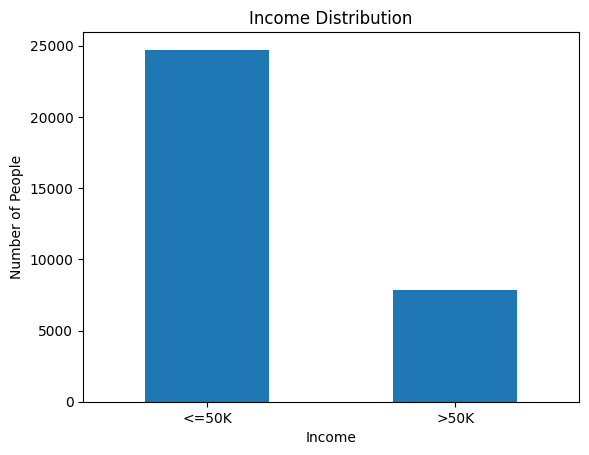

In [17]:
import matplotlib.pyplot as plt

df["income"].value_counts().plot(kind="bar")

plt.title("Income Distribution")
plt.xlabel("Income")
plt.ylabel("Number of People")
plt.xticks(rotation=0)
plt.show()

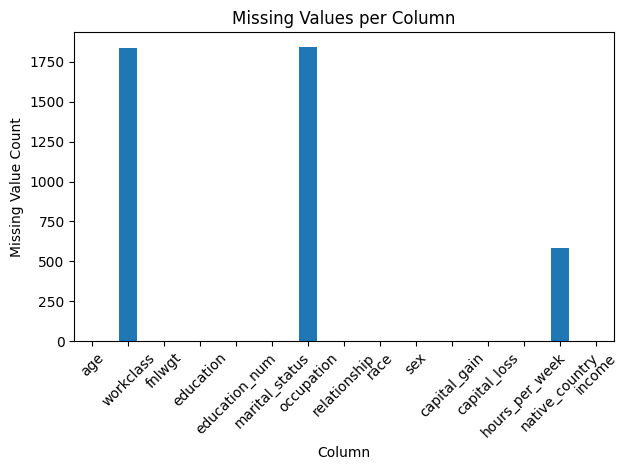

In [18]:
df.isnull().sum().plot(kind="bar")

plt.title("Missing Values per Column")
plt.xlabel("Column")
plt.ylabel("Missing Value Count")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [21]:
# ------------------------------------------------------------
# FINAL STEP: Train a model to predict income
# ------------------------------------------------------------

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix

# Create a complete machine learning pipeline
model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000))
])

# Train the model
model.fit(X_train, y_train)

# Predict income on unseen test data
y_pred = model.predict(X_test)

# Evaluate the model
print("Accuracy:", accuracy_score(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

Accuracy: 0.8558268079226163

Classification Report:
              precision    recall  f1-score   support

       <=50K       0.88      0.93      0.91      4945
        >50K       0.74      0.62      0.67      1568

    accuracy                           0.86      6513
   macro avg       0.81      0.77      0.79      6513
weighted avg       0.85      0.86      0.85      6513


Confusion Matrix:
[[4606  339]
 [ 600  968]]


PART (a): DATASET INSPECTION

First five rows:
   age         workclass  fnlwgt  education  education_num  \
0   39         State-gov   77516  Bachelors             13   
1   50  Self-emp-not-inc   83311  Bachelors             13   
2   38           Private  215646    HS-grad              9   
3   53           Private  234721       11th              7   
4   28           Private  338409  Bachelors             13   

       marital_status         occupation   relationship   race     sex  \
0       Never-married       Adm-clerical  Not-in-family  White    Male   
1  Married-civ-spouse    Exec-managerial        Husband  White    Male   
2            Divorced  Handlers-cleaners  Not-in-family  White    Male   
3  Married-civ-spouse  Handlers-cleaners        Husband  Black    Male   
4  Married-civ-spouse     Prof-specialty           Wife  Black  Female   

   capital_gain  capital_loss  hours_per_week native_country income  
0          2174             0              40  United-States  <=5

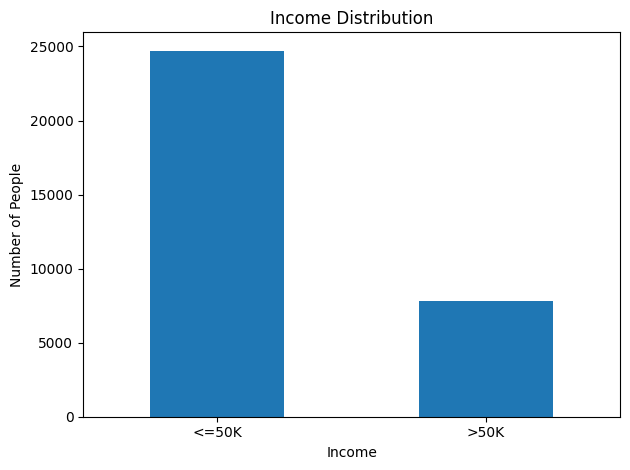

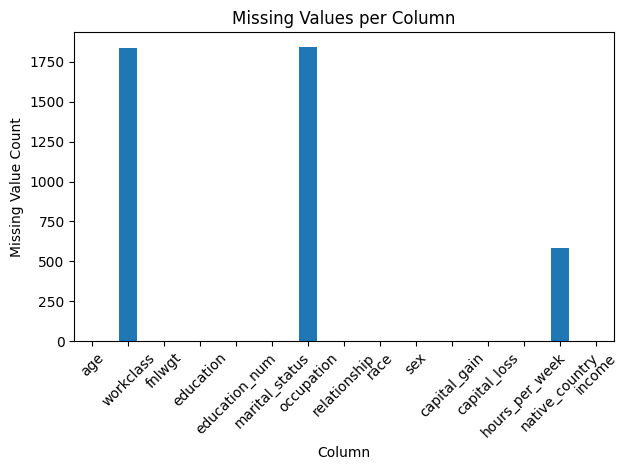

Accuracy: 0.8558268079226163

Classification Report:
              precision    recall  f1-score   support

       <=50K       0.88      0.93      0.91      4945
        >50K       0.74      0.62      0.67      1568

    accuracy                           0.86      6513
   macro avg       0.81      0.77      0.79      6513
weighted avg       0.85      0.86      0.85      6513


Confusion Matrix:
[[4606  339]
 [ 600  968]]


In [23]:

# ============================================================
# Machine Learning Assignment: Data Preprocessing Pipeline
# Dataset: UCI Adult Census Income Dataset
# Parts (a), (b), (c), and (d)
# ============================================================

import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler


# ------------------------------------------------------------
# PART (a): Load and inspect the dataset
# ------------------------------------------------------------

print("=" * 60)
print("PART (a): DATASET INSPECTION")
print("=" * 60)

url = "https://archive.ics.uci.edu/ml/machine-learning-databases/adult/adult.data"

columns = [
    "age", "workclass", "fnlwgt", "education",
    "education_num", "marital_status", "occupation",
    "relationship", "race", "sex", "capital_gain",
    "capital_loss", "hours_per_week", "native_country",
    "income"
]

df = pd.read_csv(
    url,
    names=columns,
    skipinitialspace=True,
    na_values="?"
)

print("\nFirst five rows:")
print(df.head())

print("\nDataset shape:", df.shape)

# Identify numerical and categorical columns
numerical_features = df.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = df.select_dtypes(
    include=["object", "category"]
).columns.tolist()

print("\nNumerical features:")
print(numerical_features)

print("\nCategorical features (including target):")
print(categorical_features)

# Check missing values
print("\nMissing values per column:")
print(df.isnull().sum())

print("\nTotal missing values:", df.isnull().sum().sum())

# Separate input features and target
target = "income"

X = df.drop(columns=[target])
y = df[target]

print("\nTarget variable:", target)
print("Input features shape:", X.shape)
print("Target shape:", y.shape)

print("\nTarget distribution:")
print(y.value_counts())


# ------------------------------------------------------------
# PART (b): Build the preprocessing pipeline
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("PART (b): PREPROCESSING PIPELINE")
print("=" * 60)

# Identify numerical and categorical INPUT features
numerical_features = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object", "category"]
).columns.tolist()

# Numerical pipeline: median imputation + standard scaling
numerical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical pipeline: most-frequent imputation + one-hot encoding
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine both pipelines
preprocessor = ColumnTransformer([
    ("num", numerical_pipeline, numerical_features),
    ("cat", categorical_pipeline, categorical_features)
])

# Demonstrate preprocessing on the full dataset
# (The proper train/test procedure is performed in Part (c).)
X_processed = preprocessor.fit_transform(X)

print("\nOriginal feature shape:", X.shape)
print("Processed feature shape:", X_processed.shape)
print("Preprocessing completed successfully.")


# ------------------------------------------------------------
# PART (c): Train-test split and prevent data leakage
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("PART (c): TRAIN-TEST SPLIT")
print("=" * 60)

# Split into 80% training and 20% testing data
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("\nTraining input shape:", X_train.shape)
print("Testing input shape:", X_test.shape)
print("Training target shape:", y_train.shape)
print("Testing target shape:", y_test.shape)

# Fit ONLY on training data to prevent data leakage
X_train_processed = preprocessor.fit_transform(X_train)

# Apply the learned transformations to testing data
X_test_processed = preprocessor.transform(X_test)

print("\nProcessed training shape:", X_train_processed.shape)
print("Processed testing shape:", X_test_processed.shape)

print("\nData leakage avoided: preprocessor fitted only on X_train.")


# ------------------------------------------------------------
# PART (d): Handle unseen categorical values
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("PART (d): TEST UNSEEN CATEGORIES")
print("=" * 60)

# Copy one row from the test dataset
X_unseen = X_test.iloc[[0]].copy()

# Replace workclass with a category not in the original dataset
X_unseen.loc[:, "workclass"] = "NeverSeenBefore"

print("\nUnseen category:")
print(X_unseen[["workclass"]])

# Transform using the already-fitted preprocessor
X_unseen_processed = preprocessor.transform(X_unseen)

print("\nUnseen row processed shape:", X_unseen_processed.shape)
print("Unseen category handled successfully.")


# ------------------------------------------------------------
# OPTIONAL: Visualizations (not required by the four tasks)
# ------------------------------------------------------------
import matplotlib.pyplot as plt

df["income"].value_counts().plot(kind="bar")
plt.title("Income Distribution")
plt.xlabel("Income")
plt.ylabel("Number of People")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

df.isnull().sum().plot(kind="bar")
plt.title("Missing Values per Column")
plt.xlabel("Column")
plt.ylabel("Missing Value Count")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# FINAL STEP: Train a model to predict income
# ------------------------------------------------------------

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix

# Create a complete machine learning pipeline
model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000))
])

# Train the model
model.fit(X_train, y_train)

# Predict income on unseen test data
y_pred = model.predict(X_test)

# Evaluate the model
print("Accuracy:", accuracy_score(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))
